In [4]:
# import pandas as pd

# import matplotlib.pyplot as plt

# # Read the CSV file in the same folder
# df = pd.read_csv('dynamic_A_dead_proba_R1R2.csv')

# # Plot the distribution of not_survive_probability
# plt.figure(figsize=(8, 5))
# plt.hist(1 - df['not_survive_probability'], bins=30, color='skyblue', edgecolor='black')
# plt.title('Distribution of survive_probability')
# plt.xlabel('survive_probability')
# plt.ylabel('Frequency')
# plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim((0,1.1))
# plt.show()

0 dynamic_A_dead_proba_R1R2.csv
dynamic A*
1 RL_dead_proba_R1R2.csv
proposed MARL
2 static_A_dead_proba_R1R2.csv
static A*
3 SUMO_dead_proba_R1R2.csv
SUMO DUE


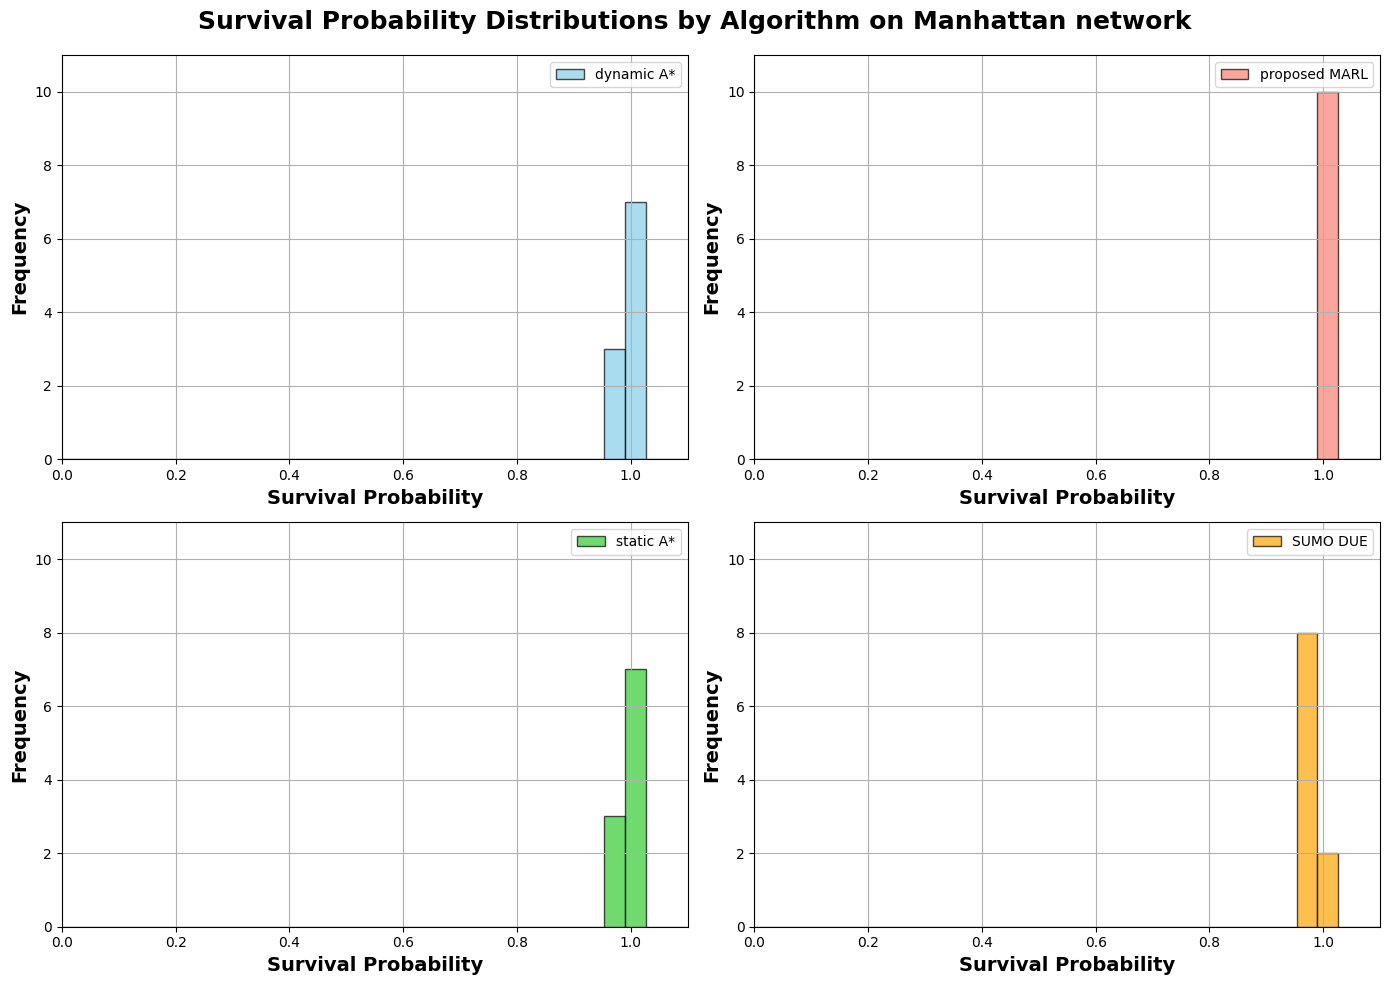

In [5]:
import glob
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Find all CSV files in the current folder
csv_files = glob.glob("*.csv")

# Mapping from file name to algorithm name
algorithm_map = {
    'dynamic_A_dead_proba_R1R2.csv': 'dynamic A*',
    'static_A_dead_proba_R1R2.csv': 'static A*',
    'SUMO_dead_proba_R1R2.csv': 'SUMO DUE',
    'RL_dead_proba_R1R2.csv': 'proposed MARL'
}


# Color palette—make sure it matches number of files
color_list = ['skyblue', 'salmon', 'limegreen', 'orange']

# Define fixed bin edges for uniformity
x_min, x_max = 0, 1.1
bins = np.linspace(x_min, x_max, 31)  # 30 bins

# Calculate global y_max for consistent ylim
y_max = 0
for file in csv_files:
    data = pd.read_csv(file)
    counts, _ = np.histogram(data['survival_probability'], bins=bins)
    y_max = max(y_max, max(counts))

# Prepare a 2x2 plot
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

# Plot each histogram
for idx, file in enumerate(csv_files):
    print(idx, file)
    algo_name = algorithm_map.get(file, file)
    data = pd.read_csv(file)
    survive_prob = data['survival_probability']
    color = color_list[idx % len(color_list)]

    axes[idx].hist(survive_prob, bins=bins, alpha=0.7, color=color, edgecolor='black', label=algo_name)
    print(algo_name)
    # axes[idx].set_title(f'{algo_name} Distribution')
    axes[idx].set_xlabel('Survival Probability')
    axes[idx].set_ylabel('Frequency')
    axes[idx].set_xlim(x_min, x_max)
    axes[idx].set_ylim(0, y_max+1)
    axes[idx].grid(True)
    axes[idx].legend()

    axes[idx].set_xlabel('Survival Probability', fontsize=14, fontweight='bold')
    axes[idx].set_ylabel('Frequency', fontsize=14, fontweight='bold')


# Adjust layout
plt.tight_layout(rect=[0, 0, 1, 0.95])

fig.suptitle('Survival Probability Distributions by Algorithm on Manhattan network', fontsize=18, fontweight='bold')

plt.show()
